# Dataset Validity Check

This notebook validates the manifest-only dataset prepared for `mil_baseline`.

Checks included:
- labels JSON schema and value ranges,
- file existence under the configured slides root,
- class distribution,
- duplicate slide IDs,
- OpenSlide readability spot checks.
- Slide thumbnail grid and label-count bar plot.

In [1]:
%matplotlib inline

In [2]:
from __future__ import annotations

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    import openslide
except Exception as exc:
    openslide = None
    print(f"OpenSlide not available: {exc}")

ROOT = Path(".").resolve().parent
PREP_DIR = ROOT / ".mnt" / "nfs-data" / "prepared_mil_dataset"
PREPARED_LABELS = PREP_DIR / "labels_prepared.json"
PREPARE_REPORT = PREP_DIR / "prepare_report.json"
SLIDES_ROOT = ROOT / ".mnt" / "nfs-data"
NUM_CLASSES = 3
SPOT_CHECK_N = 10


In [3]:
with open(PREPARED_LABELS, "r", encoding="utf-8") as f:
    rows = json.load(f)

assert isinstance(rows, list), "Prepared labels must be a list"

validated = []
schema_errors = []
for idx, row in enumerate(rows):
    if not isinstance(row, dict):
        schema_errors.append((idx, "row is not an object"))
        continue
    image = row.get("image")
    label = row.get("label")
    if not isinstance(image, str):
        schema_errors.append((idx, f"image is not string: {image!r}"))
        continue
    if not isinstance(label, int):
        schema_errors.append((idx, f"label is not int: {label!r}"))
        continue
    if label < 1 or label > NUM_CLASSES:
        schema_errors.append((idx, f"label out of range: {label}"))
        continue
    abs_path = SLIDES_ROOT / image
    slide_id = Path(image).stem
    validated.append({
        "idx": idx,
        "image": image,
        "label": label,
        "slide_id": slide_id,
        "abs_path": abs_path,
        "exists": abs_path.exists(),
    })

df = pd.DataFrame(validated)
print(f"rows_total={len(rows)} validated={len(df)} schema_errors={len(schema_errors)}")
if schema_errors:
    print("First schema errors:")
    for err in schema_errors[:10]:
        print(err)

display(df.head())

rows_total=22 validated=22 schema_errors=0


,idx,image,label,slide_id,abs_path,exists
0,0,2024/slide-2024-04-03T07-52-35-R1-S2.mrxs,3,slide-2024-04-03T07-52-35-R1-S2,/workspace/Custom.Dataset.Nottingham/.mnt/nfs-...,True
1,1,2024/slide-2024-04-03T07-57-44-R1-S3.mrxs,2,slide-2024-04-03T07-57-44-R1-S3,/workspace/Custom.Dataset.Nottingham/.mnt/nfs-...,True
2,2,2024/slide-2024-04-03T08-04-15-R1-S4.mrxs,2,slide-2024-04-03T08-04-15-R1-S4,/workspace/Custom.Dataset.Nottingham/.mnt/nfs-...,True
3,3,2024/slide-2024-04-03T08-06-24-R1-S5.mrxs,2,slide-2024-04-03T08-06-24-R1-S5,/workspace/Custom.Dataset.Nottingham/.mnt/nfs-...,True
4,4,2024/slide-2024-04-03T08-11-41-R1-S6.mrxs,1,slide-2024-04-03T08-11-41-R1-S6,/workspace/Custom.Dataset.Nottingham/.mnt/nfs-...,True


In [4]:
missing_df = df[~df["exists"]].copy()
dupe_slide_ids = df[df.duplicated("slide_id", keep=False)].sort_values("slide_id")
class_counts = Counter(df["label"].tolist())

print("Class distribution:")
for cls in sorted(class_counts):
    print(f"  class_{cls}: {class_counts[cls]}")

print(f"Missing files: {len(missing_df)}")
if len(missing_df):
    display(missing_df[["image", "label", "abs_path"]].head(20))

print(f"Duplicate slide_ids: {len(dupe_slide_ids)}")
if len(dupe_slide_ids):
    display(dupe_slide_ids[["slide_id", "image", "label"]])

if PREPARE_REPORT.exists():
    with open(PREPARE_REPORT, "r", encoding="utf-8") as f:
        report = json.load(f)
    print("\nPreparation report summary:")
    print(
        f"prepared={report.get('n_prepared')} missing={report.get('n_missing')} ambiguous={report.get('n_ambiguous')}"
    )

Class distribution:
  class_1: 5
  class_2: 11
  class_3: 6
Missing files: 0
Duplicate slide_ids: 0

Preparation report summary:
prepared=22 missing=20 ambiguous=0


In [5]:
if openslide is None:
    print("Skip OpenSlide checks: openslide-python is not available.")
else:
    existing_df = df[df["exists"]].copy().reset_index(drop=True)
    sample_df = existing_df.head(SPOT_CHECK_N)
    print(f"OpenSlide spot checks: {len(sample_df)} slide(s)")

    checks = []
    for _, row in sample_df.iterrows():
        path = Path(row["abs_path"])
        ok = True
        err = None
        level_count = None
        dimensions = None
        try:
            slide = openslide.OpenSlide(str(path))
            level_count = int(slide.level_count)
            dimensions = tuple(int(x) for x in slide.dimensions)
            slide.close()
        except Exception as exc:
            ok = False
            err = str(exc)

        checks.append(
            {
                "image": row["image"],
                "ok": ok,
                "error": err,
                "level_count": level_count,
                "dimensions": dimensions,
            }
        )

    checks_df = pd.DataFrame(checks)
    display(checks_df)
    failed = checks_df[~checks_df["ok"]]
    print(f"OpenSlide failures: {len(failed)}")
    if len(failed):
        display(failed[["image", "error"]])

OpenSlide spot checks: 10 slide(s)


,image,ok,error,level_count,dimensions
0,2024/slide-2024-04-03T07-52-35-R1-S2.mrxs,True,None,9,"(76472, 181940)"
1,2024/slide-2024-04-03T07-57-44-R1-S3.mrxs,True,None,9,"(76472, 181940)"
2,2024/slide-2024-04-03T08-04-15-R1-S4.mrxs,True,None,9,"(76472, 181940)"
3,2024/slide-2024-04-03T08-06-24-R1-S5.mrxs,True,None,9,"(76472, 181940)"
4,2024/slide-2024-04-03T08-11-41-R1-S6.mrxs,True,None,9,"(76472, 181940)"
5,2024/slide-2024-04-03T08-15-46-R1-S7.mrxs,True,None,9,"(76472, 181940)"
6,2024/slide-2024-04-03T08-20-24-R1-S8.mrxs,True,None,9,"(76472, 181940)"
7,2024/slide-2024-04-03T08-24-42-R1-S9.mrxs,True,None,9,"(76472, 181940)"
8,2024/slide-2024-04-03T08-28-06-R1-S10.mrxs,True,None,9,"(76472, 181940)"
9,2024/slide-2024-04-03T08-31-34-R1-S11.mrxs,True,None,9,"(76472, 181940)"


OpenSlide failures: 0


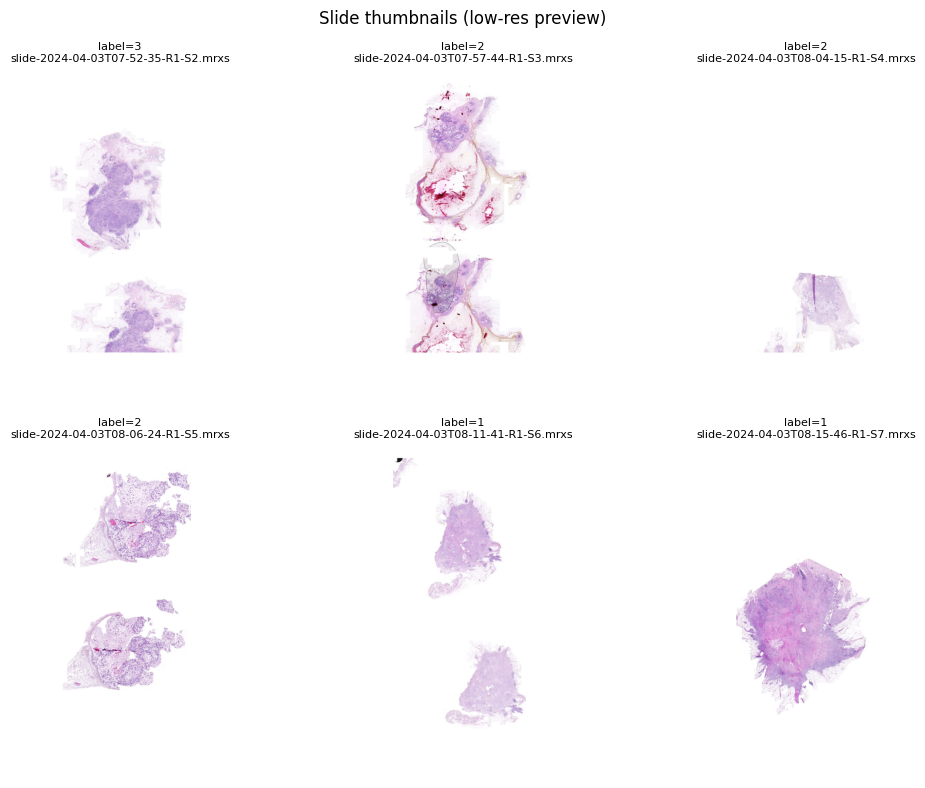

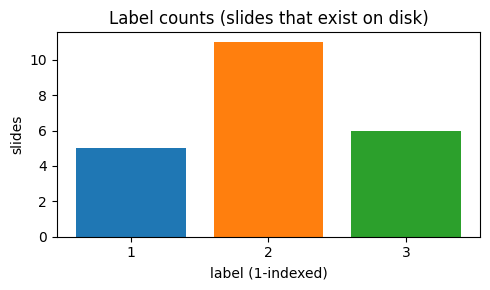

In [6]:
# Preview one slide at low resolution (avoid reading full level-0 region)
THUMB_MAX_PX = 768


def slide_thumbnail_rgb(path: Path, max_px: int = THUMB_MAX_PX):
    """Return an RGB PIL image sized for display (~max_px long edge)."""
    from PIL import Image

    slide = openslide.OpenSlide(str(path))
    try:
        if hasattr(slide, "get_thumbnail"):
            return slide.get_thumbnail((max_px, max_px)).convert("RGB")

        lw0, lh0 = slide.dimensions
        target_ds = max(lw0, lh0) / float(max_px)
        level = max(
            0,
            min(slide.level_count - 1, slide.get_best_level_for_downsample(target_ds)),
        )
        w, h = slide.level_dimensions[level]
        rgb = slide.read_region((0, 0), level, (w, h)).convert("RGB")
        if max(w, h) > max_px:
            scale = max_px / max(w, h)
            nw, nh = int(w * scale), int(h * scale)
            try:
                resample = Image.Resampling.LANCZOS
            except AttributeError:
                resample = Image.LANCZOS
            rgb = rgb.resize((nw, nh), resample=resample)
        return rgb
    finally:
        slide.close()


if openslide is None:
    print("OpenSlide unavailable; skip thumbnails.")
else:
    usable = df[df["exists"]].copy()
    if usable.empty:
        print("No existing slides to preview.")
    else:
        n_preview = min(6, len(usable))
        cols = min(3, n_preview)
        rows = int(np.ceil(n_preview / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows), squeeze=False)
        for idx in range(rows * cols):
            r, c = divmod(idx, cols)
            ax = axes[r][c]
            if idx < n_preview:
                row = usable.iloc[idx]
                thumb_path = Path(row["abs_path"])
                pil_rgb = slide_thumbnail_rgb(thumb_path)
                ax.imshow(np.asarray(pil_rgb))
                ax.set_title(f"label={row['label']}\n{Path(row['image']).name}", fontsize=8)
            ax.axis("off")
        fig.suptitle("Slide thumbnails (low-res preview)", fontsize=12)
        plt.tight_layout()
        plt.show()

        fig2, ax2 = plt.subplots(figsize=(5, 3))
        counts = usable["label"].value_counts().sort_index()
        ax2.bar([str(int(i)) for i in counts.index], counts.values, color=[f"C{k}" for k in range(len(counts))])
        ax2.set_xlabel("label (1-indexed)")
        ax2.set_ylabel("slides")
        ax2.set_title("Label counts (slides that exist on disk)")
        plt.tight_layout()
        plt.show()